In [ ]:
## !/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/7/2022
# version ='1.0'

### Demo: the relations between the steepest descent for quadratic norm and the change of coordinate

In the text book {book-convex-2004}, section 9.4, 'Steepest descent method', the relations between the steepest descent for non-quadratic norm and the change of coordinate was reviewed. In this demo, some experiments are designed to visualize the relations.

In this demo, the minimization problem is a non-quadratic problem in $R^2$,

$$
f(x_1, x_2) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}
$$

By setting $\nabla f(x_1,x_2)=0$, the minimum is attained at $x^*=(0.5\log(0.5), 0)$.

In the demo, three quadratic norms are defined

$$
P_0 = \left[\begin{array}{cc}
1 & 0 \\
0 & 1 \\
\end{array} \right],
P_1 = \left[\begin{array}{cc}
0.5 & 0 \\
0 & 2 \\
\end{array}\right],
P_2 = \left[\begin{array}{cc}
2 & 0 \\
0 & 0.5 \\
\end{array} \right]
$$
(which are different than those in the text book, for the purpose of standardization)

The firstexperiment result is for the steepest descent method under different quadratic norm, comparing to the gradient descent method under associated changes of coordinates.


The second experiment result is for the convergence speed for the steepest descent with norm $\parallel \cdot \parallel_{P}$.


More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).


In [16]:
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib import patches

$f(x_1, x_2) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}$

The derivatives of $f(x)$, i.e., $\nabla f(x)$ can be derived accordingly.

The normalized steepest descent direction is calculated as in section 9.4.1 $\Delta x_{nsd} = -(\nabla f(x)^T P^{-1} \nabla f(x))^{-1/2} P^{-1}\nabla f(x)$.


In [17]:
def my_f(x):
    """
    $f(x_1, x_2) = e^{x_1+3x_2-0.1}+e^{x_1-3x_2-0.1}+e^{-x_1-0.1}$
    :param x:
    :return:
    """
    x1 = x[0]
    x2 = x[1]
    return math.exp(x1 + 3 * x2 - 0.1) + math.exp(x1 - 3 * x2 - 0.1) + math.exp(-x1 - 0.1)


def my_derivative_f(x):
    """
    Calculate the derivatives of $f(x)$, i.e., $\nabla f(x)$
    :param x:
    :return:
    """
    x1 = x[0]
    x2 = x[1]
    derivative_1 = 1 * math.exp(x1 + 3 * x2 - 0.1) + 1 * math.exp(x1 - 3 * x2 - 0.1) - math.exp(-x1 - 0.1)
    derivative_2 = 3 * math.exp(x1 + 3 * x2 - 0.1) - 3 * math.exp(x1 - 3 * x2 - 0.1)
    return np.array([derivative_1, derivative_2])


def my_steepest_descent_direction(x, P):
    """
    calculate the normalized steepest descent direction as in section 9.4.1
    $\Delta x_{nsd} = -(\nabla f(x)^T P^{-1} \nabla f(x))^{-1/2} P^{-1}\nabla f(x)$
    :param x:
    :param P:
    :return:
    """
    sd = -1 * np.linalg.inv(P) @ my_derivative_f(x)
    nsd = (my_derivative_f(x).T @ np.linalg.inv(P) @ my_derivative_f(x)) ** (-1/2) * sd
    return nsd


def backtracking_line_search(f, df, x, delta_x, alpha, beta):
    """
    The backtracking line search method
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :return:
    """
    t = 1
    while f(x + delta_x * t) > f(x) + alpha * t * np.dot(df(x), delta_x):
        t = beta * t
    return t

 Plot the convergence of the steepest descent method under different quadratic norm, $P_1, P_2, P_3$

In [18]:
def plot_convergence_steepest_descent_under_different_quadratic_norm(P1, P2, P3, ax1, ax2, ax3):
    """
    plot the convergence of the steepest descent method under different quadratic norm, $P_1, P_2, P_3$
    :param P1:
    :param P2:
    :param P3:
    :param ax1:
    :param ax2:
    :param ax3:
    :return:
    """
    min_x1 = -6
    max_x1 = 6
    min_x2 = -6
    max_x2 = 6
    delta = 0.1
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([x1, x2]))

    Ps = [P1, P2, P3]
    axs = [ax1, ax2, ax3]
    N = len(Ps)
    for i in range(len(Ps)):
        P = Ps[i]
        ax = axs[i]
        levels = np.arange(0, 200, 1)
        CS = ax.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=100)
        ax.clabel(CS, fontsize=6, inline=True)
        ax.set_xlabel(r'$x_1$')
        ax.set_ylabel(r'$x_2$')
        ax.set_title(r'$f(x)$')

        alpha = 0.1
        beta = 0.7

        x0 = np.array([-2, 2])
        num_iter = 20
        x = x0

        delta_x = my_steepest_descent_direction(x, P)
        x_points_2 = np.zeros([num_iter, 2])
        fx_2 = np.zeros([num_iter, 1])
        for iter in range(num_iter):

            if iter < 2:
                e2 = patches.Ellipse((x[0], x[1]),
                                     2 * math.sqrt(1/P[0, 0]),
                                     2 * math.sqrt(1/P[1, 1]),
                                     linewidth=2, fill=False, zorder=2, color='orange')
                ax.add_patch(e2)

            x_points_2[iter] = x
            fx_2[iter] = my_f(x)
            t = backtracking_line_search(my_f, my_derivative_f, x, delta_x, alpha, beta)
            x_next = x + t * delta_x
            x = x_next
            delta_x = my_steepest_descent_direction(x_next, P)

        ax.plot(x_points_2[:, 0], x_points_2[:, 1], color='C2', marker='x', label=r'$P_{}$'.format(i))
        ax.legend()
        ax.set_aspect('equal', adjustable='box')

Refer to section 9.4.1, Interpretation via change of coordinates $\bar{f}(\bar{x}) = f(P^{-1/2}\bar{x})$

Its derivaties is calculated as $\nabla \bar{f}(\bar{x}) = P^{-1/2} \nabla f(x)$

Its steepest descent direction is calculated as,

$\Delta \bar{x}_{sd} = \nabla \bar{f}(\bar{x})$

$\Delta \bar{x}_{nsd} = \dfrac{\Delta \bar{x}_{sd}}{|\Delta \bar{x}_{sd}|}$

In [19]:
def my_f_bar(x_bar, P):
    """
    Refer to section 9.4.1, Interpretation via change of coordinates
    $\bar{f}(\bar{x}) = f(P^{-1/2}\bar{x})$
    :param x_bar:
    :param P:
    :return:
    """
    x = np.linalg.inv(np.sqrt(P)) @ x_bar
    return my_f(x)


def backtracking_line_search_bar(f_bar, df_bar, x, delta_x, alpha, beta, P):
    """
    The backtracking line search method for $\bar{f}$
    :param f_bar:
    :param df_bar:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param P:
    :return:
    """
    t = 1
    while f_bar(x + delta_x * t, P) > f_bar(x, P) + alpha * t * np.dot(df_bar(x, P), delta_x):
        t = beta * t
    return t


def my_derivative_f_bar(x_bar, P):
    """
    $\nabla \bar{f}(\bar{x}) = P^{-1/2} \nabla f(x)$
    :param x_bar:
    :param P:
    :return:
    """
    x = np.linalg.inv(np.sqrt(P)) @ x_bar
    return np.linalg.inv(np.sqrt(P)) @ my_derivative_f(x)


def my_descent_direction(x_bar, P):
    """
    $\Delta \bar{x}_{sd} = \nabla \bar{f}(\bar{x})$
    $\Delta \bar{x}_{nsd} = \dfrac{\Delta \bar{x}_{sd}}{|\Delta \bar{x}_{sd}|}$
    :param x_bar:
    :param P:
    :return:
    """
    sd = -my_derivative_f_bar(x_bar, P)
    nsd = (my_derivative_f_bar(x_bar, P).T @ my_derivative_f_bar(x_bar, P)) ** (-1/2) * sd
    return nsd

Plot the convergence of the steepest descent method under different coordinate changes $P_1, P_2, P_3$

In [20]:
def plot_convergence_steepest_descent_under_different_coordinate_changes(P1, P2, P3, ax1, ax2, ax3):
    """
    Plot the convergence of the steepest descent method under different coordinate changes $P_1, P_2, P_3$
    :param P1:
    :param P2:
    :param P3:
    :param ax1:
    :param ax2:
    :param ax3:
    :return:
    """
    min_x1 = -6
    max_x1 = 6
    min_x2 = -6
    max_x2 = 6
    delta = 0.1
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    Ps = [P1, P2, P3]
    axs = [ax1, ax2, ax3]

    N = len(Ps)
    for i in range(len(Ps)):
        P = Ps[i]
        for x1_i in range(len(x)):
            for x2_i in range(len(y)):
                x1 = x[x1_i]
                x2 = y[x2_i]
                Z[x2_i][x1_i] = my_f_bar(np.array([x1, x2]), P)

        ax = axs[i]
        levels = np.arange(0, 200, 1)
        CS = ax.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=100)
        ax.clabel(CS, fontsize=6, inline=True)
        ax.set_xlabel(r'$x_1$')
        ax.set_ylabel(r'$x_2$')
        ax.set_title(r'$f(x)$')

        alpha = 0.1
        beta = 0.7

        x0 = np.array([-2, 2])
        x0_bar = np.sqrt(P) @ x0
        num_iter = 20
        x_bar = x0_bar
        delta_x_bar = my_descent_direction(x0_bar, P)
        x_points_2 = np.zeros([num_iter, 2])
        fx_2 = np.zeros([num_iter, 1])
        for iter in range(num_iter):

            if iter < 2:
                e2 = patches.Ellipse((x_bar[0], x_bar[1]),
                                     2 * math.sqrt(1),
                                     2 * math.sqrt(1),
                                     linewidth=2, fill=False, zorder=2, color='orange')
                ax.add_patch(e2)
            x_points_2[iter] = x_bar
            fx_2[iter] = my_f_bar(x_bar, P)
            t = backtracking_line_search_bar(my_f_bar, my_derivative_f_bar, x_bar, delta_x_bar, alpha, beta, P)
            x_next = x_bar + t * delta_x_bar

            x_bar = x_next
            delta_x_bar = my_descent_direction(x_next, P)

        ax.plot(x_points_2[:, 0], x_points_2[:, 1], color='C2', marker='x', label=r'$P_{}$'.format(i))
        ax.legend()
        ax.set_aspect('equal', adjustable='box')

Plot the comparison of the convergence speed of the steepest descent method under different quadratic norm

In [21]:
def plot_quadratic_norm_convergence_speed_comparison(P1, P2, P3, ax):
    """
    Plot the comparison of the convergence speed of the steepest descent method under different quadratic norm
    """
    min_x1 = -6
    max_x1 = 6
    min_x2 = -6
    max_x2 = 6
    delta = 0.1
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    f_min = my_f(np.array([0.5 * math.log(0.5), 0]))

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([x1, x2]))

    Ps = [P1, P2, P3]
    N = len(Ps)
    for i in range(len(Ps)):
        P = Ps[i]
        levels = np.arange(0, 200, 1)
        alpha = 0.1
        beta = 0.7

        x0 = np.array([-2, 2])
        num_iter = 40
        x = x0

        delta_x = my_steepest_descent_direction(x, P)

        x_points_2 = np.zeros([num_iter, 2])
        fx_2 = np.zeros([num_iter, 1])
        for iter in range(num_iter):
            x_points_2[iter] = x
            fx_2[iter] = my_f(x)
            t = backtracking_line_search(my_f, my_derivative_f, x, delta_x, alpha, beta)
            x_next = x + t * delta_x
            x = x_next
            delta_x = my_steepest_descent_direction(x_next, P)

        ax.semilogy(fx_2 - f_min, marker='x', label=r'$P_{}$'.format(i))
    ax.legend()
    ax.set_xlabel(r'$iteration$')
    ax.set_ylabel(r'$f(x)-p^*$')
    ax.grid()
    plt.show()

In [22]:
def plot_2d_graph():
    plt.figure(figsize=(12, 8))
    ax1 = plt.subplot(2, 3, 1)
    ax2 = plt.subplot(2, 3, 2)
    ax3 = plt.subplot(2, 3, 3)
    P1 = np.array([[1, 0], [0, 1]])
    P2 = np.array([[0.5, 0], [0, 2]])
    P3 = np.array([[2, 0], [0, 0.5]])
    plot_convergence_steepest_descent_under_different_quadratic_norm(P1, P2, P3, ax1, ax2, ax3)

    ax1 = plt.subplot(2, 3, 4)
    ax2 = plt.subplot(2, 3, 5)
    ax3 = plt.subplot(2, 3, 6)
    plot_convergence_steepest_descent_under_different_coordinate_changes(P1, P2, P3, ax1, ax2, ax3)
    plt.show()

def plot_convergence_speed_line():
    ax = plt.subplot(1, 1, 1)
    P1 = np.array([[1, 0], [0, 1]])
    P2 = np.array([[0.5, 0], [0, 2]])
    P3 = np.array([[2, 0], [0, 0.5]])
    plot_quadratic_norm_convergence_speed_comparison(P1, P2, P3, ax=ax)
    plt.show()

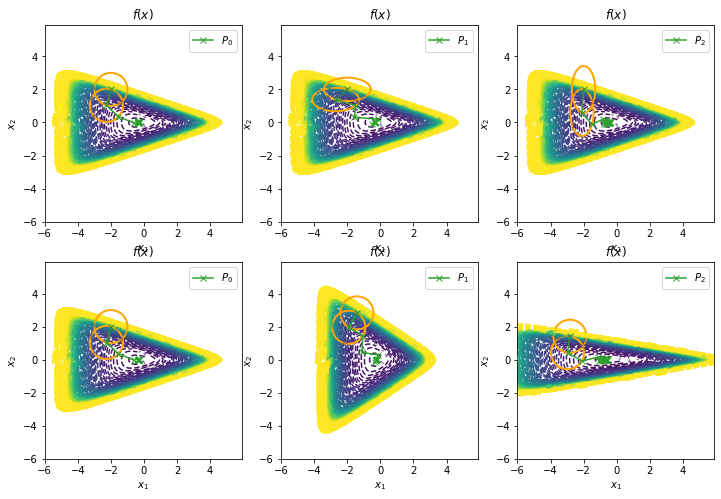

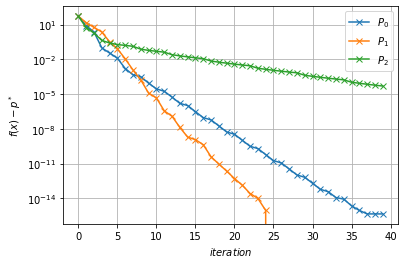

In [23]:
if __name__ == "__main__":
    plot_2d_graph()
    plot_convergence_speed_line()